# Explore GB1 data

**Goal:** Identify sequence, fitness and split columns. Inspect missing values and mutation counts. Investigating 4 AA sequence
GB1 is small protein domain from Streptococcus Protein G
Aim is to see if ML can predict how mutations in GB1 affect binding fitness.
Dataset comes from FLIP benchmark and contains variant amino acid substitutions and resultant fitness.

In [1]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Everything is working!")

PyTorch: 2.14.1+cpu
Everything is working!


In [2]:
from pathlib import Path

data_dir = Path.cwd().parent / "data"

print(list(data_dir.iterdir()))

[WindowsPath('c:/Users/mw645/OneDrive/ML Project/protein-ml-project/data/processed'), WindowsPath('c:/Users/mw645/OneDrive/ML Project/protein-ml-project/data/raw')]


In [3]:
#check whether GB1 CSV is in data/raw
raw_dir = data_dir / "raw"

for file in raw_dir.iterdir():
    print(file.name)

.gitkeep
four_mutations_full_data.csv.zip


In [4]:
#load experimental data
import pandas as pd

file_path = raw_dir / "four_mutations_full_data.csv.zip"

df = pd.read_csv(file_path, compression="zip")

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

df.head()

Dataset shape: (149361, 17)
Column names: ['Variants', 'HD', 'Count input', 'Count selected', 'Fitness', 'sequence', 'keep', 'one_vs_rest', 'one_vs_rest_validation', 'two_vs_rest', 'two_vs_rest_validation', 'three_vs_rest', 'three_vs_rest_validation', 'sampled', 'sampled_validation', 'low_vs_high', 'low_vs_high_validation']


C:\Users\mw645\AppData\Local\Temp\ipykernel_1912\3739577632.py:6: DtypeWarning: Columns (8: one_vs_rest_validation, 10: two_vs_rest_validation, 12: three_vs_rest_validation) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path, compression="zip")


,Variants,HD,Count input,Count selected,Fitness,sequence,keep,one_vs_rest,one_vs_rest_validation,two_vs_rest,two_vs_rest_validation,three_vs_rest,three_vs_rest_validation,sampled,sampled_validation,low_vs_high,low_vs_high_validation
0,VDGV,0,92735,338346,1.000000,MQYKLILNGKTLKGETTTEAVDAATAEKVFKQYANDNGVDGEWTYD...,True,train,NaN,train,NaN,train,NaN,train,NaN,test,NaN
1,ADGV,1,34,43,0.061910,MQYKLILNGKTLKGETTTEAVDAATAEKVFKQYANDNGADGEWTYD...,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,CDGV,1,850,641,0.242237,MQYKLILNGKTLKGETTTEAVDAATAEKVFKQYANDNGCDGEWTYD...,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,DDGV,1,63,63,0.006472,MQYKLILNGKTLKGETTTEAVDAATAEKVFKQYANDNGDDGEWTYD...,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,EDGV,1,841,190,0.032719,MQYKLILNGKTLKGETTTEAVDAATAEKVFKQYANDNGEDGEWTYD...,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


HD - no of subs relative to WT
Count input/output - sequencing counts before/after experimental selection. 
keep - whether variant is retained for the benchmark
one_vs_rest - predefined training/test assignments 
*_validation - validation assignments for the corresponding benchmark splits

In [ ]:
#explore the dataset
# Number of variants and dataset columns
print("Dataset shape:", df.shape)

# Number of variants at each mutation distance
print("\nMutation distribution:")
print(df["HD"].value_counts().sort_index())

# Summary of experimental fitness measurements
print("\nFitness statistics:")
print(df["Fitness"].describe())

# Number of variants retained for the benchmark
print("\nVariants retained:")
print(df["keep"].value_counts())

Dataset shape: (149361, 17)

Mutation distribution:
HD
0         1
1        76
2      2091
3     26019
4    121174
Name: count, dtype: int64

Fitness statistics:
count    149361.000000
mean          0.080510
std           0.395391
min           0.000000
25%           0.001370
50%           0.003384
75%           0.008986
max           8.761966
Name: Fitness, dtype: float64

Variants retained:
keep
False    140628
True       8733
Name: count, dtype: int64


Most AA combinations in the dataset perform poorly in binding assay, but some improvements possible.
Only 8733 out of 149,361 variants marked keep=true - selected subset by FLIP

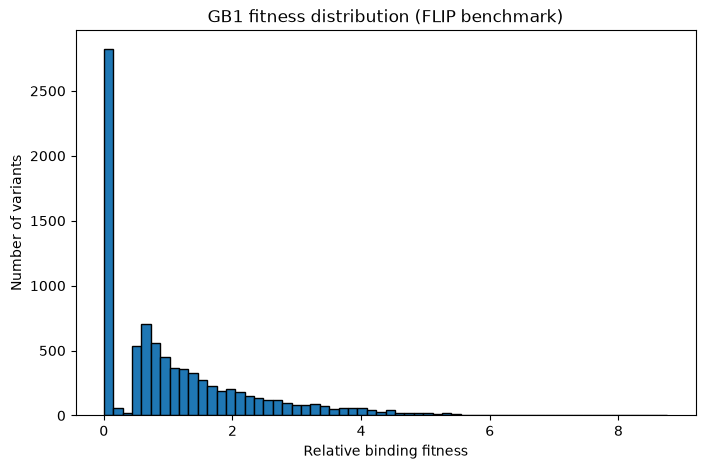

In [6]:
#Visualise the fitness landscape
# Select variants retained in the benchmark
df_model = df[df["keep"] == True].copy()

# Plot the fitness distribution
plt.figure(figsize=(8, 5))

plt.hist(
    df_model["Fitness"],
    bins=60,
    edgecolor="black"
)

plt.xlabel("Relative binding fitness")
plt.ylabel("Number of variants")
plt.title("GB1 fitness distribution (FLIP benchmark)")

plt.show()

Note only looking at the 8733 variants with keep=true - may not reflect full experimental landscape - can see this below.

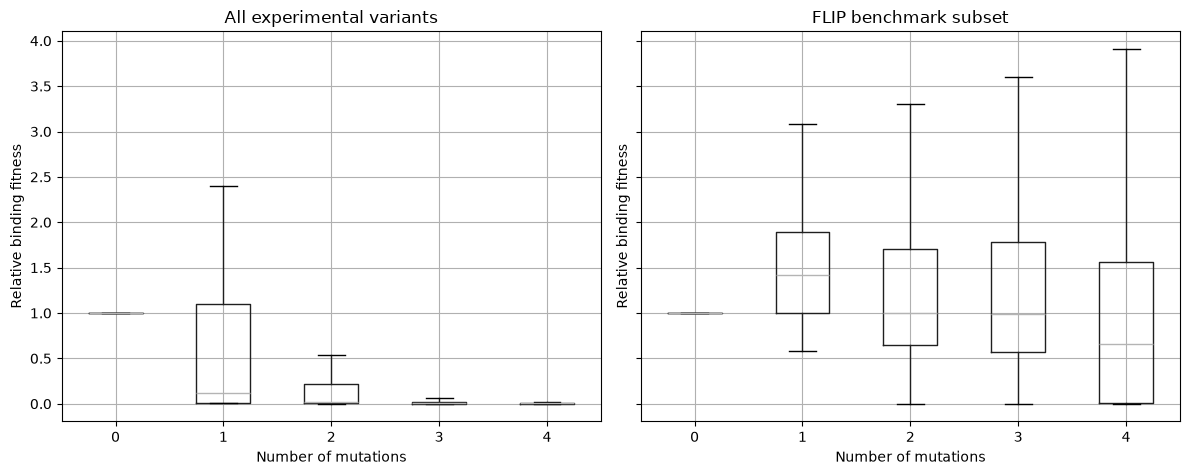

In [8]:
#compare both data sets
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, data, title in zip(
    axes,
    [df, df_model],
    ["All experimental variants", "FLIP benchmark subset"]
):
    data.boxplot(
        column="Fitness",
        by="HD",
        ax=ax,
        showfliers=False
    )

    ax.set_title(title)
    ax.set_xlabel("Number of mutations")
    ax.set_ylabel("Relative binding fitness")

plt.suptitle("")
plt.tight_layout()
plt.show()

Potential dataset bias and distribution shift. More so: How well do sequence-based machine-learning models generalise across different regions of a protein fitness landscape?

In [ ]:
#understand how FLIP divides the retained vairants into training and testing groups 
split_columns = [
    "one_vs_rest",
    "two_vs_rest",
    "three_vs_rest",
    "sampled",
    "low_vs_high"
]

for col in split_columns:
    print(f"\n{col}")
    print(df_model[col].value_counts(dropna=False))


one_vs_rest
one_vs_rest
test     8705
train      28
Name: count, dtype: int64

two_vs_rest
two_vs_rest
test     8309
train     424
Name: count, dtype: int64

three_vs_rest
three_vs_rest
test     5743
train    2990
Name: count, dtype: int64

sampled
sampled
train    6988
test     1745
Name: count, dtype: int64

low_vs_high
low_vs_high
train    5089
test     3644
Name: count, dtype: int64


These are all different experiments eg. two_vs_rest is can a model trained on variants with up to two mutations predict more complex variants ? Sampled: Can a model trained on lower-fitness variants predict higher-fitness variants? Will start with sampled.

Preliminary observation: The full GB1 experimental dataset shows a substantial reduction in median binding fitness as mutation distance increases. In contrast, the FLIP benchmark subset contains a higher proportion of functional variants, including proteins with multiple substitutions. This highlights the importance of dataset selection when evaluating machine-learning models for protein fitness prediction.

In [ ]:
#separate training and testing data - predefined sampled experiment
train_df = df_model[df_model["sampled"] == "train"].copy()
test_df = df_model[df_model["sampled"] == "test"].copy()

print("Training:", len(train_df))
print("Testing:", len(test_df))

Training: 6988
Testing: 1745
